# Детекция бабочек: демо четырёх моделей

Выберите Python из `.venv` проекта. Подготовка окружения, CUDA llama.cpp и параметры описаны в [MODELS.md](MODELS.md).

Ноутбук использует тот же Hydra-конфиг и пайплайн, что и CLI. Модели работают **последовательно на CUDA**. `test` считает метрики по эталонам, `inference` обрабатывает изображения без использования правильных ответов. Предсказания, сырые ответы, ошибки и seed каждой попытки сохраняются в отдельный каталог и логируются в Comet.

По умолчанию запускается Grounding DINO на четырёх воспроизводимо выбранных изображениях validation, включая отрицательный пример. Это демонстрация, а не сравнение качества на полном наборе.

In [1]:
from pathlib import Path
import os
import json
import logging
from datetime import datetime

# Работает при открытии из репозитория или его родительского каталога.
PROJECT = Path.cwd()
if not (PROJECT / "butterfly_bench").is_dir():
    PROJECT = PROJECT / "shad_razmetka_final_project_26"
if not (PROJECT / "butterfly_bench").is_dir():
    raise RuntimeError("Откройте ноутбук из каталога репозитория")
os.chdir(PROJECT)

from dotenv import load_dotenv
load_dotenv()
from butterfly_bench.api import configure
from butterfly_bench.pipeline import run
from butterfly_bench.data import load_samples, open_sample
from butterfly_bench.visualize import draw_prediction
from omegaconf import OmegaConf
import pandas as pd
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO, format="%(message)s")
logging.getLogger("httpx2").setLevel(logging.WARNING)
logging.getLogger("httpx").setLevel(logging.WARNING)
print("Проект:", PROJECT)

Проект: /home/xartik/hse/26-27/shad_crowdsoursing_final_project/shad_razmetka_final_project_26


## Настройки

`MODEL_NAMES` может содержать одну или несколько моделей: `owlv2`, `grounding_dino`, `qwen`, `gemma`. Первые три используют Transformers без квантования; Gemma — llama.cpp и UD-Q4_K_XL.

Для своих изображений задайте `DATA_SOURCE="manifest"`, `MANIFEST_PATH` и `MODE="inference"`. В JSONL нужны `photo_id` и `image_path` либо `photo_url`. `PHOTO_IDS` выбирает конкретные ID; `LIMIT=None` обрабатывает весь выбранный набор. В режиме inference эталоны не используются.

Для конкурсного набора: `DATA_SOURCE="manifest"`, `MANIFEST_PATH="dataset.jsonl"`, `MODE="inference"`, `LIMIT=None`, `PHOTO_IDS=None`, `SHUFFLE=False`. Полный прогон выполняется только после изменения этих настроек. Ключ Comet берётся из окружения или локального конфига; в ноутбук его вставлять не нужно.

In [2]:
MODEL_NAMES = ["grounding_dino"]
MODE = "test"                     # test | inference
DATA_SOURCE = "hf"                # hf | manifest
SPLIT = "validation"              # validation | test (400 golden-set images)
MANIFEST_PATH = "dataset.jsonl"
IMAGE_ROOT = "images"
PHOTO_IDS = None                   # например [755630032, 760199895]
LIMIT = 4                         # None — весь набор
SHUFFLE = True
SEED = 42
COMET_MODE = "auto"               # auto | online | offline | disabled
MAX_ATTEMPTS = 3                   # полное число попыток на изображение
NMS_IOU = None                     # например 0.5; отдельный эксперимент

# Независимые промпты и дополнительные Hydra overrides для каждой модели.
# Без замены Qwen и Gemma начинают с одинакового подробного промпта.
PROMPTS = {}
MODEL_OVERRIDES = {
    "owlv2": [],                   # например ["model.threshold=0.2"]
    "grounding_dino": [],
    "qwen": [],
    "gemma": [],
}
OUTPUT_BASE = PROJECT / "outputs" / "demo" / datetime.now().strftime("%Y-%m-%d_%H-%M-%S-%f")

configs = []
for name in MODEL_NAMES:
    overrides = [f"model={name}", f"mode={MODE}", f"data={DATA_SOURCE}",
                 f"seed={SEED}", f"comet.mode={COMET_MODE}"]
    overrides += MODEL_OVERRIDES.get(name, [])
    cfg = configure(overrides, output_dir=OUTPUT_BASE / name)
    cfg.data.limit = LIMIT
    cfg.data.photo_ids = PHOTO_IDS
    cfg.data.shuffle = SHUFFLE
    cfg.retries.max_attempts = MAX_ATTEMPTS
    cfg.postprocess.nms_iou = NMS_IOU
    if DATA_SOURCE == "hf":
        cfg.data.split = SPLIT
    else:
        cfg.data.path = MANIFEST_PATH
        cfg.data.image_root = IMAGE_ROOT
    if name in PROMPTS:
        cfg.model.prompt = PROMPTS[name]
    configs.append(cfg)

samples, data_info = load_samples(configs[0].data, MODE, SEED)
print("ID для всех моделей:", data_info["photo_ids"])
print("Режим:", MODE, "| Изображений:", len(samples))
print("Результаты:", OUTPUT_BASE)
print("Промпт первой модели:\n", configs[0].model.prompt)

/home/xartik/hse/26-27/shad_crowdsoursing_final_project/shad_razmetka_final_project_26/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ID для всех моделей: [751709802, 751411373, 760728314, 755545567]
Режим: test | Изображений: 4
Результаты: /home/xartik/hse/26-27/shad_crowdsoursing_final_project/shad_razmetka_final_project_26/outputs/demo/2026-11-13_19-14-25-030754
Промпт первой модели:
 butterfly


## Запуск

Каждая модель загружается, обрабатывает весь выбранный набор и освобождает ресурсы перед следующей. Сбой изображения остаётся явной ошибкой; модель может повторить ответ после ошибки JSON или схемы. Невалидный ответ не превращается в успешный пустой список. Файл `submission.jsonl` создаётся только при успешной обработке всех выбранных ID.

In [3]:
results = []
for cfg in configs:
    result = run(cfg)
    results.append(result)
    print(cfg.model.name, result["status"], result["output_dir"])

summary = []
for cfg, result in zip(configs, results, strict=True):
    metrics = result["metrics"]
    row = {"model": cfg.model.name, "status": result["status"]}
    fields = ["images", "f1", "iou_0.75/f1", "precision", "recall", "errors",
              "negative_fp", "processing_errors", "parsing_errors", "validation_errors",
              "mean_image_seconds", "processing_seconds", "device_peak_used_mib"]
    row.update({key: metrics.get(key) for key in fields})
    comet = json.loads((Path(result["output_dir"]) / "comet.json").read_text())
    row["comet_url"] = comet.get("url", "offline/disabled")
    summary.append(row)
display(pd.DataFrame(summary))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.


COMET INFO: Experiment is live on comet.com https://www.comet.com/ubileyka19/butterfly-bench/a9e48e7ebd504f71b8718950728e5a79



Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Loading weights:  86%|████████▌ | 841/978 [00:00<00:00, 8407.90it/s]

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 8411.49it/s]

1/4 photo_id=751709802 boxes=1 attempts=1 seconds=0.616


... (99 outputs left out)

COMET INFO: Please wait for assets to finish uploading (timeout is 60 seconds)


COMET INFO: All assets have been sent, waiting for delivery confirmation


grounding_dino complete /home/xartik/hse/26-27/shad_crowdsoursing_final_project/shad_razmetka_final_project_26/outputs/demo/2026-11-13_19-14-25-030754/grounding_dino


,model,status,images,f1,iou_0.75/f1,precision,recall,errors,negative_fp,processing_errors,parsing_errors,validation_errors,mean_image_seconds,processing_seconds,device_peak_used_mib,comet_url
0,grounding_dino,complete,4,0.666667,0.444444,0.6,0.75,3,2,0,0,0,0.273027,1.092107,2039.0,https://www.comet.com/ubileyka19/butterfly-ben...


## Посмотреть рамки

**Красные** рамки — предсказание модели; **зелёные** — эталон, если выбран `test`. Ошибка обработки подписывается отдельно. Ниже отображаются первые четыре выбранных изображения для каждой модели. Наличие корректного JSON и допустимых координат не доказывает правильность детекции.

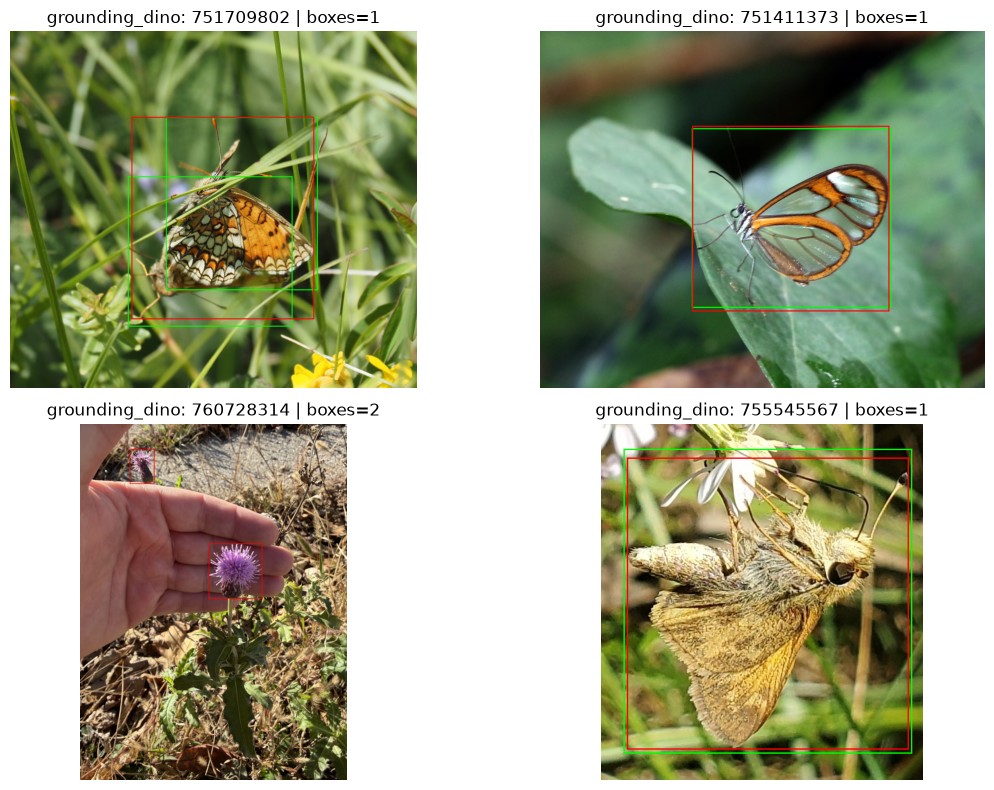

In [4]:
preview_count = min(4, len(samples))
for cfg, result in zip(configs, results, strict=True):
    path = Path(result["output_dir"]) / "predictions.jsonl"
    predictions = {row["photo_id"]: row for row in map(json.loads, path.read_text().splitlines())}
    fig, axes = plt.subplots(1 if preview_count <= 2 else 2, min(2, preview_count),
                             figsize=(12, 4 if preview_count <= 2 else 8), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    for axis, sample in zip(axes.flat, samples[:preview_count]):
        prediction = predictions[sample.photo_id]
        annotated = draw_prediction(open_sample(sample), prediction, sample.truth)
        annotated.thumbnail((800, 800))
        axis.imshow(annotated)
        status = "ERROR" if prediction["error"] else f"boxes={len(prediction['boxes'])}"
        axis.set_title(f"{cfg.model.name}: {sample.photo_id} | {status}")
    plt.tight_layout()
    plt.show()

## Сырые ответы и ошибки

`stage=parsing` означает, что текст нельзя принять как одну JSONL-строку; `validation` — JSON/структура получены, но нарушена схема или геометрия; `runtime` — ошибка открытия изображения, инференса или обращения к серверу. После последней неудачной попытки в предсказании записаны `boxes=null` и причина ошибки.

В метриках `errors=FP+FN` — ошибки детекции, а `processing_errors` — число изображений с окончательным техническим отказом. Ошибки отдельных попыток считаются отдельно.

In [5]:
run_dir = Path(results[0]["output_dir"])
attempts = [json.loads(line) for line in (run_dir / "attempts.jsonl").read_text().splitlines()]
attempts_table = pd.DataFrame(attempts)
columns = [c for c in ["photo_id", "attempt", "seed", "stage", "seconds", "error", "raw_text"]
           if c in attempts_table.columns]
display(attempts_table[columns].head(20))

submission = run_dir / "submission.jsonl"
if submission.exists():
    print("Файл для выбранных ID:", submission)
    print(submission.read_text()[:2000])
else:
    print("Есть окончательные ошибки; submission.jsonl не создан. См. attempts.jsonl.")

,photo_id,attempt,seed,stage,seconds,raw_text
0,751709802,1,2560946164,success,0.616167,None
1,751411373,1,2259831303,success,0.162578,None
2,760728314,1,3070690180,success,0.179346,None
3,755545567,1,2136265753,success,0.133691,None


Файл для выбранных ID: /home/xartik/hse/26-27/shad_crowdsoursing_final_project/shad_razmetka_final_project_26/outputs/demo/2026-11-13_19-14-25-030754/grounding_dino/submission.jsonl
{"photo_id": 751709802, "boxes": [{"left": 0.29854917526245117, "top": 0.24033609458378383, "width": 0.4486500024795532, "height": 0.5680119480405535}], "error": null}
{"photo_id": 751411373, "boxes": [{"left": 0.34313224283854166, "top": 0.2652477264404297, "width": 0.44238517252604165, "height": 0.5213637034098307}], "error": null}
{"photo_id": 760728314, "boxes": [{"left": 0.18621941407521567, "top": 0.07066361606121063, "width": 0.09272519747416179, "height": 0.0982775092124939}, {"left": 0.4822695255279541, "top": 0.33549174666404724, "width": 0.20040551821390787, "height": 0.1555267572402954}], "error": null}
{"photo_id": 755545567, "boxes": [{"left": 0.08011046214083747, "top": 0.09489601726568038, "width": 0.8750846256272065, "height": 0.8185222099318622}], "error": null}



## Полный запуск из терминала

```bash
# Все модели, весь validation; обработка последовательно
python -m butterfly_bench -m model=owlv2,grounding_dino,qwen,gemma

# Инференс конкурсного манифеста без эталонов
python -m butterfly_bench mode=inference model=grounding_dino data=manifest data.path=dataset.jsonl

# Эксперимент: меняем только NMS, данные остаются теми же
python -m butterfly_bench -m model=owlv2 postprocess.nms_iou=null,0.5
```

Ни ноутбук, ни CLI не отправляют предсказания в Контест и не делают push в GitHub. Для повторного запуска ячейки запуска сначала выполните ячейку настроек: она создаст новый каталог, чтобы не перезаписать результаты.